In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms

# Penambahan Library
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from PIL import Image
import random
import time
import copy
import json
import matplotlib.pyplot as plt

In [ ]:
# Pengecekan Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
# Pengecekan Dataset
ds = datasets.OxfordIIITPet(
    root='data',
    download=True,
    target_types='category',
)

# Cek Jenis-Jenis Class
for i in range(len(ds.classes)):
  print(ds.classes[i])

Abyssinian
American Bulldog
American Pit Bull Terrier
Basset Hound
Beagle
Bengal
Birman
Bombay
Boxer
British Shorthair
Chihuahua
Egyptian Mau
English Cocker Spaniel
English Setter
German Shorthaired
Great Pyrenees
Havanese
Japanese Chin
Keeshond
Leonberger
Maine Coon
Miniature Pinscher
Newfoundland
Persian
Pomeranian
Pug
Ragdoll
Russian Blue
Saint Bernard
Samoyed
Scottish Terrier
Shiba Inu
Siamese
Sphynx
Staffordshire Bull Terrier
Wheaten Terrier
Yorkshire Terrier


In [ ]:
# Input Dataset (Train + Val)
dsA = datasets.OxfordIIITPet(
    root='data',
    split='trainval',
    download=True,
    transform=ToTensor(),
    target_types='category',
)

# Input Dataset (Test)
dsB = datasets.OxfordIIITPet(
    root='data',
    split='test',
    download=True,
    transform=ToTensor(),
    target_types='category',
)

# Pembagian Kelas
classes = ['abyssinian', 'bengal', 'birman', 'bombay', 'british shorthair', 'american bulldog', 'american pit bull terrier', 'basset hound', 'beagle', 'boxer']

In [ ]:
# Preprocessing Dataset
allPaths = list(dsA._images) + list(dsB._images)
allLabels = list(dsA._labels) + list(dsB._labels)

print('Images Before Filtering:', len(allPaths))

idx = {}
for i in range(len(dsA.classes)):
  name = dsA.classes[i].lower()
  idx[name] = i

keep = {}
newLabel = 0
for name in classes:
  originalNumber = idx[name]
  keep[originalNumber] = newLabel
  newLabel += 1

paths = []
labels = []
for i in range(len(allPaths)):
  originalLabel = allLabels[i]
  if originalLabel in keep:
    paths.append(allPaths[i])
    labels.append(keep[allLabels[i]])

labels = np.array(labels)
print('Images After Filtering:', len(paths))
print('Images Per Class:', np.bincount(labels))

Images Before Filtering: 7349
Images After Filtering: 1981
Images Per Class: [198 200 200 184 200 200 200 200 200 199]


In [ ]:
# Splitting Dataset
allNumbers = np.arange(len(paths))

train_idx, temp_idx = train_test_split(allNumbers, test_size=0.3, stratify=labels, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, stratify=labels[temp_idx], random_state=42)

print('Train:', len(train_idx))
print('Validation:', len(val_idx))
print('Test:', len(test_idx))

Train: 1386
Validation: 297
Test: 298


In [ ]:
# Pengambilan Data Secara Pasangan (image + label)
class petDataset(Dataset):
  def __init__(self, idx, transform):
    self.idx = idx
    self.transform = transform

  def __len__(self):
    return len(self.idx)

  def __getitem__(self, position):
    imageNumber = self.idx[position]
    image = Image.open(paths[imageNumber]).convert('RGB')
    image = self.transform(image)
    label = int(labels[imageNumber])
    return image, label

In [ ]:
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

def countParams(model):
  trainable = 0
  total = 0
  for param in model.parameters():
    total += param.numel()
    if param.requires_grad:
      trainable += param.numel()
  return trainable, total

In [ ]:
# 4. Pipeline Transformasi Data (???)
# Data latih: menerapkan augmentasi aktif
train_transforms = transforms.Compose([
  transforms.Resize(256),
  transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.RandomRotation(degrees=15),
  transforms.ColorJitter(brightness=0.2, contrast=0.2),
  transforms.ToTensor(),
  transforms.Normalize(mean=weights.transforms().mean,
  std=weights.transforms().std),
])

# Data validasi/uji: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()

#
valLoader = DataLoader(petDataset(val_idx, eval_transforms), batch_size=32, shuffle=False)
testLoader = DataLoader(petDataset(test_idx, eval_transforms), batch_size=32, shuffle=False)

In [ ]:
# Pembuatan Setiap Model
def buildModel1():
  model = models.resnet18(weights=None)
  model.fc = nn.Linear(model.fc.in_features, 10)
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-2)
  return model.to(device), optimizer

def buildModel2():
  model = models.resnet18(weights=weights)
# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
  for param in model.parameters():
    param.requires_grad = False
# Ganti classifier head untuk 10 kelas
  num_features = model.fc.in_features
  model.fc = nn.Linear(num_features, 10)
  optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3, weight_decay=1e-2)
  return model.to(device), optimizer

def buildModel3():
  model = models.resnet18(weights=weights)
  for param in model.parameters():
    param.requires_grad = False
  model.fc = nn.Linear(model.fc.in_features, 10)
# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
  for param in model.layer4.parameters():
    param.requires_grad = True
# Optimasi dengan Differential Learning Rate
  optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
  ], weight_decay=1e-2)
  return model.to(device), optimizer

In [ ]:
# Verifikasi parameter yang dapat dilatih
def countParams(model):
  trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
  total_params = sum(p.numel() for p in model.parameters())
  return trainable_params, total_params

modelCheck, _ = buildModel1()
trainable, total = countParams(modelCheck)
print('Parameters (Trainable / Total): {:,} / {:,}'.format(trainable, total))

modelCheck, _ = buildModel2()
trainable, total = countParams(modelCheck)
print('Parameters (Trainable / Total): {:,} / {:,}'.format(trainable, total))

modelCheck, _ = buildModel3()
trainable, total = countParams(modelCheck)
print('Parameters (Trainable / Total): {:,} / {:,}'.format(trainable, total))

Parameters (Trainable / Total): 11,181,642 / 11,181,642
Parameters (Trainable / Total): 5,130 / 11,181,642
Parameters (Trainable / Total): 8,398,858 / 11,181,642


In [ ]:
# Persiapan Training
criterion = nn.CrossEntropyLoss()
results = []
histories = {}

def trainMode(model):
  model.train()
  for module in model.modules():
    if isinstance(module, nn.BatchNorm2d):
      is_frozen = True
      for param in module.parameters():
        if param.requires_grad:
          is_frozen = False
      if is_frozen:
        module.eval()

def trainEpoch(model, loader, optimizer):
    trainMode(model)
    total_loss = 0.0
    correct = 0
    count = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        outputs = model(images)
        loss = criterion(outputs, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss = total_loss + loss.item() * len(targets)
        predicted = outputs.argmax(dim=1)
        correct = correct + (predicted == targets).sum().item()
        count = count + len(targets)

    return total_loss / count, correct / count

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    count = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            total_loss = total_loss + loss.item() * len(targets)
            predicted = outputs.argmax(dim=1)
            correct = correct + (predicted == targets).sum().item()
            count = count + len(targets)

            all_predictions.extend(predicted.cpu().tolist())
            all_targets.extend(targets.cpu().tolist())

    return total_loss / count, correct / count, all_predictions, all_targets

In [ ]:
# Training Logic

def set_seed():
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

def training(codeName, strategy, buildFunction, trainTransform, maxEpochs=25, patience=4):
#   Pengunaan Seed Yang Sama
    set_seed()
    model, optimizer = buildFunction()
    trainLoader = DataLoader(petDataset(train_idx, trainTransform),
                              batch_size=32, shuffle=True, num_workers=2)

#   Mencatat setup
    trainable, total = countParams(model)
    lrList = []
    for group in optimizer.param_groups:
        lrList.append(str(group["lr"]))
    lr_text = " / ".join(lrList)

#   Training Looping Dengan Stop Awal Di Validation Loss
    history = []
    bestValLoss = 999999.0
    bestEpoch = 0
    bestWeights = None
    epochsWithoutImprovement = 0

    startTime = time.time()
    for epoch in range(1, maxEpochs + 1):
        trainLoss, trainAcc = trainEpoch(model, trainLoader, optimizer)
        valLoss, valAcc, _, _ = evaluate(model, valLoader)

        history.append({"epoch": epoch, "trainLoss": trainLoss, "trainAcc": trainAcc,
                        "valLoss": valLoss, "valAcc": valAcc})
        print(codeName, "epoch", epoch,
              "| train loss", round(trainLoss, 3), "acc", round(trainAcc, 3),
              "| val loss", round(valLoss, 3), "acc", round(valAcc, 3))

        if valLoss < bestValLoss:
            bestValLoss = valLoss
            bestEpoch = epoch
            bestWeights = copy.deepcopy(model.state_dict())
            epochsWithoutImprovement = 0
        else:
            epochsWithoutImprovement = epochsWithoutImprovement + 1
            if epochsWithoutImprovement >= patience:
                print("Early stopping at epoch", epoch)
                break
    trainingTime = time.time() - startTime

#   Mencari Epoch Terbaik
    model.load_state_dict(bestWeights)

#   Penilaian Terakhir
    cleanTrainLoader = DataLoader(petDataset(train_idx, eval_transforms),
                                    batch_size=32, shuffle=False, num_workers=2)
    _, trainAcc, _, _ = evaluate(model, cleanTrainLoader)
    _, valAcc, _, _ = evaluate(model, valLoader)
    _, testAcc, testPredictions, testTargets = evaluate(model, testLoader)
    testF1 = f1_score(testTargets, testPredictions, average="macro")

#   Penyimpanan Hasil
    row = {
        "code": codeName,
        "strategy": strategy,
        "trainableParams": trainable,
        "totalParams": total,
        "learningRates": lr_text,
        "epochsRun": len(history),
        "bestEpoch": bestEpoch,
        "trainTime_s": round(trainingTime, 1),
        "trainAcc": round(trainAcc, 4),
        "valAcc": round(valAcc, 4),
        "overfitGap": round(trainAcc - valAcc, 4),
        "testAcc": round(testAcc, 4),
        "testMacroF1": round(testF1, 4),
    }
    results.append(row)
    histories[codeName] = history
    print(row)

    return model

In [ ]:
# Training Model B1
modelB1 = training('B1', 'From Scratch', buildModel1, train_transforms, maxEpochs=5)

B1 epoch 1 | train loss 2.335 acc 0.182 | val loss 2.177 acc 0.215
B1 epoch 2 | train loss 2.101 acc 0.246 | val loss 4.262 acc 0.148
B1 epoch 3 | train loss 2.142 acc 0.224 | val loss 2.249 acc 0.209
B1 epoch 4 | train loss 2.088 acc 0.25 | val loss 2.299 acc 0.155
B1 epoch 5 | train loss 2.042 acc 0.249 | val loss 2.081 acc 0.205
{'code': 'B1', 'strategy': 'From Scratch', 'trainableParams': 11181642, 'totalParams': 11181642, 'learningRates': '0.001', 'epochsRun': 5, 'bestEpoch': 5, 'trainTime_s': 79.5, 'trainAcc': 0.2395, 'valAcc': 0.2054, 'overfitGap': 0.0342, 'testAcc': 0.2383, 'testMacroF1': 0.2402}


In [ ]:
# Training Model B2
modelB2 = training('B2', 'Feature Extraction', buildModel2, train_transforms, maxEpochs=5)

B2 epoch 1 | train loss 1.382 acc 0.575 | val loss 0.701 acc 0.842
B2 epoch 2 | train loss 0.574 acc 0.887 | val loss 0.419 acc 0.929
B2 epoch 3 | train loss 0.423 acc 0.904 | val loss 0.389 acc 0.869
B2 epoch 4 | train loss 0.332 acc 0.922 | val loss 0.325 acc 0.926
B2 epoch 5 | train loss 0.305 acc 0.927 | val loss 0.269 acc 0.936
{'code': 'B2', 'strategy': 'Feature Extraction', 'trainableParams': 5130, 'totalParams': 11181642, 'learningRates': '0.001', 'epochsRun': 5, 'bestEpoch': 5, 'trainTime_s': 75.3, 'trainAcc': 0.9423, 'valAcc': 0.936, 'overfitGap': 0.0063, 'testAcc': 0.9195, 'testMacroF1': 0.9193}


In [ ]:
# Training Model B3
modelB3 = training('B3', 'Fine Tuning', buildModel3, train_transforms, maxEpochs=5)

B3 epoch 1 | train loss 0.78 acc 0.765 | val loss 0.214 acc 0.933
B3 epoch 2 | train loss 0.222 acc 0.938 | val loss 0.182 acc 0.96
B3 epoch 3 | train loss 0.142 acc 0.964 | val loss 0.235 acc 0.916
B3 epoch 4 | train loss 0.081 acc 0.983 | val loss 0.2 acc 0.943
B3 epoch 5 | train loss 0.056 acc 0.985 | val loss 0.208 acc 0.946
{'code': 'B3', 'strategy': 'Fine Tuning', 'trainableParams': 8398858, 'totalParams': 11181642, 'learningRates': '0.0001 / 0.001', 'epochsRun': 5, 'bestEpoch': 2, 'trainTime_s': 73.8, 'trainAcc': 0.974, 'valAcc': 0.9596, 'overfitGap': 0.0144, 'testAcc': 0.9329, 'testMacroF1': 0.9327}


In [ ]:
# Training Model B4
modelB4 = training('B4', 'Fine Tuning (No Augmentation)', buildModel3, eval_transforms, maxEpochs=5)

B4 epoch 1 | train loss 0.691 acc 0.802 | val loss 0.227 acc 0.933
B4 epoch 2 | train loss 0.111 acc 0.973 | val loss 0.191 acc 0.953
B4 epoch 3 | train loss 0.034 acc 0.998 | val loss 0.217 acc 0.933
B4 epoch 4 | train loss 0.016 acc 1.0 | val loss 0.191 acc 0.949
B4 epoch 5 | train loss 0.009 acc 1.0 | val loss 0.198 acc 0.943
{'code': 'B4', 'strategy': 'Fine Tuning (No Augmentation)', 'trainableParams': 8398858, 'totalParams': 11181642, 'learningRates': '0.0001 / 0.001', 'epochsRun': 5, 'bestEpoch': 4, 'trainTime_s': 52.8, 'trainAcc': 1.0, 'valAcc': 0.9495, 'overfitGap': 0.0505, 'testAcc': 0.943, 'testMacroF1': 0.9431}


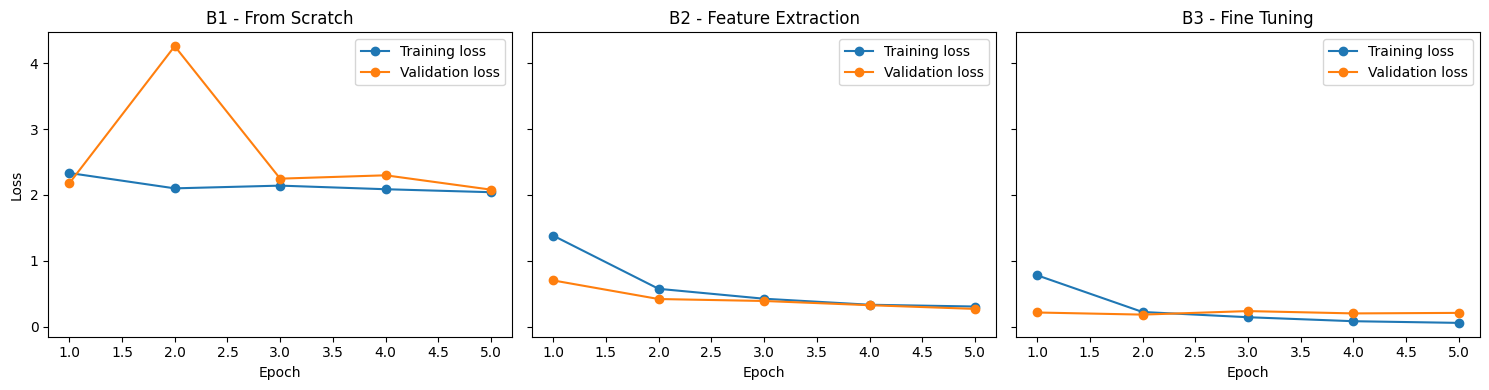

In [ ]:
# Bagian C1
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, code in zip(axes, ['B1', 'B2', 'B3']):
    h = histories[code]
    ep = [r['epoch'] for r in h]
    ax.plot(ep, [r['trainLoss'] for r in h], marker='o', label='Training loss')
    ax.plot(ep, [r['valLoss'] for r in h], marker='o', label='Validation loss')
    ax.set_title(code + ' - ' + table.loc[table.code == code, 'strategy'].iloc[0])
    ax.set_xlabel('Epoch')
    ax.legend()
axes[0].set_ylabel('Loss')
plt.tight_layout()
plt.savefig('C1_loss_curves.png', dpi=150)
plt.show()

Total errors: 20 of 298


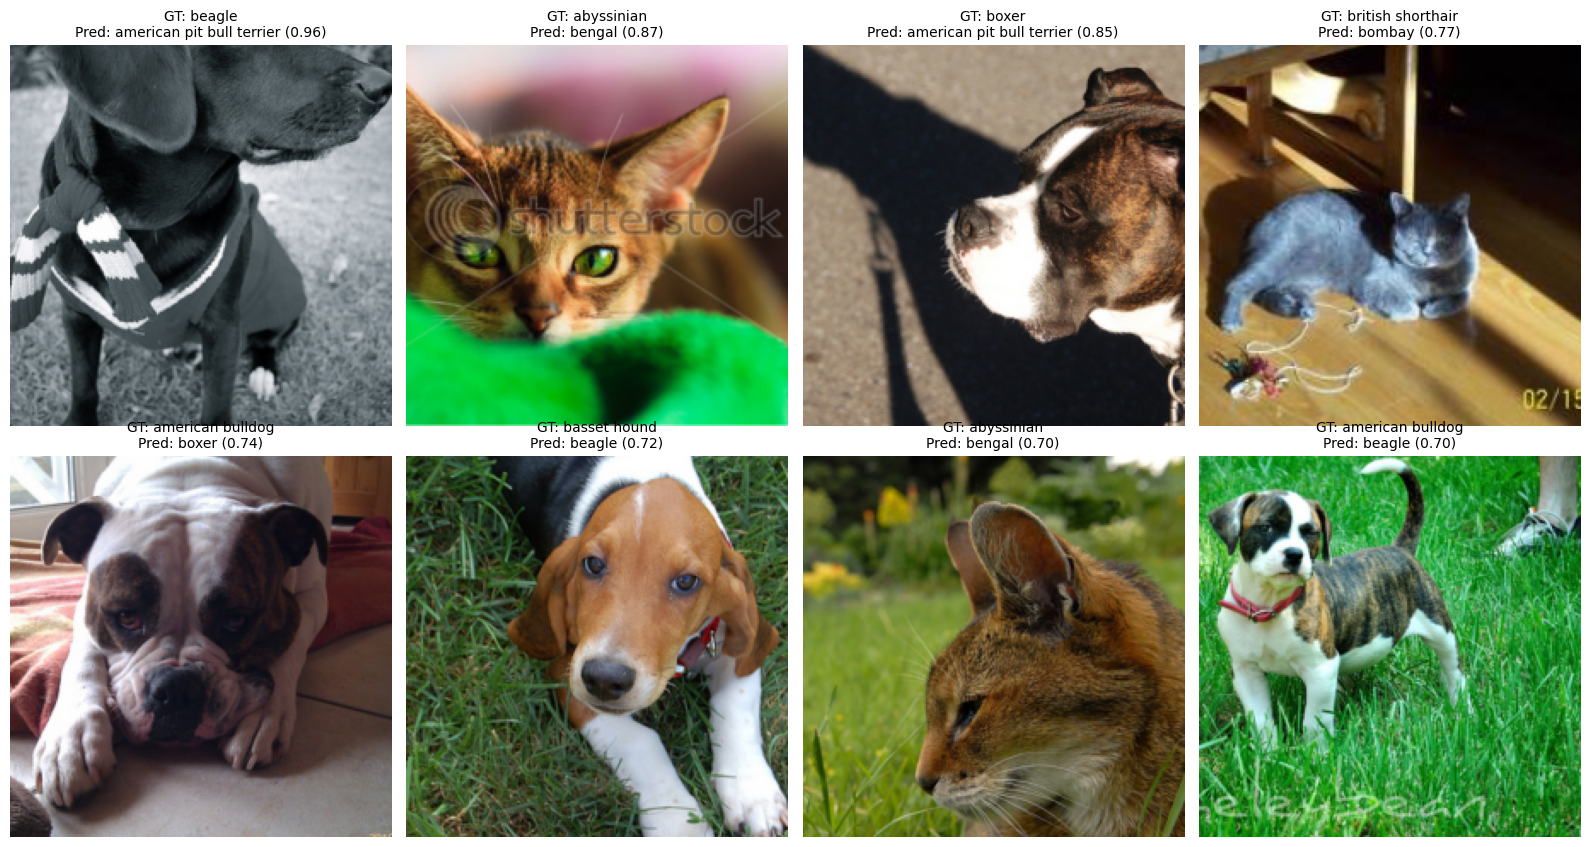

1 GT: beagle | Pred: american pit bull terrier | conf: 0.961 | data/oxford-iiit-pet/images/beagle_198.jpg
2 GT: abyssinian | Pred: bengal | conf: 0.872 | data/oxford-iiit-pet/images/Abyssinian_101.jpg
3 GT: boxer | Pred: american pit bull terrier | conf: 0.853 | data/oxford-iiit-pet/images/boxer_187.jpg
4 GT: british shorthair | Pred: bombay | conf: 0.768 | data/oxford-iiit-pet/images/British_Shorthair_230.jpg
5 GT: american bulldog | Pred: boxer | conf: 0.738 | data/oxford-iiit-pet/images/american_bulldog_48.jpg
6 GT: basset hound | Pred: beagle | conf: 0.717 | data/oxford-iiit-pet/images/basset_hound_126.jpg
7 GT: abyssinian | Pred: bengal | conf: 0.702 | data/oxford-iiit-pet/images/Abyssinian_61.jpg
8 GT: american bulldog | Pred: beagle | conf: 0.699 | data/oxford-iiit-pet/images/american_bulldog_68.jpg


In [ ]:
# Bagian C3
bestCode = 'B3'
bestModel = {'B2': modelB2, 'B3': modelB3, 'B4': modelB4}[bestCode]

bestModel.eval()
errors = []
pos = 0
with torch.no_grad():
    for images, targets in testLoader:
        probs = torch.softmax(bestModel(images.to(device)), dim=1).cpu()
        conf, pred = probs.max(dim=1)
        for i in range(len(targets)):
            if pred[i].item() != targets[i].item():
                errors.append({'testPos': pos + i, 'true': targets[i].item(),
                               'pred': pred[i].item(), 'conf': conf[i].item()})
        pos += len(targets)

print('Total errors:', len(errors), 'of', len(test_idx))
errors.sort(key=lambda e: -e['conf'])
shown = errors[:8]

showTf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, e in zip(axes.flat, shown):
    img = Image.open(paths[test_idx[e['testPos']]]).convert('RGB')
    ax.imshow(showTf(img))
    ax.set_title('GT: {}\nPred: {} ({:.2f})'.format(classes[e['true']], classes[e['pred']], e['conf']), fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig('C3_failures.png', dpi=150)
plt.show()

for k, e in enumerate(shown, 1):
    print(k, 'GT:', classes[e['true']], '| Pred:', classes[e['pred']], '| conf: %.3f' % e['conf'],
          '|', paths[test_idx[e['testPos']]])

In [ ]:
resultsTable = pd.DataFrame(results)
resultsTable.to_csv('Results Summary.csv', index=False)

with open('Training History.json', 'w') as file:
  json.dump({'seed': 42, 'histories': histories}, file, indent=2)

resultsTable

,code,strategy,trainableParams,totalParams,learningRates,epochsRun,bestEpoch,trainTime_s,trainAcc,valAcc,overfitGap,testAcc,testMacroF1
0,B1,From Scratch,11181642,11181642,0.001,5,5,79.5,0.2395,0.2054,0.0342,0.2383,0.2402
1,B2,Feature Extraction,5130,11181642,0.001,5,5,75.3,0.9423,0.9360,0.0063,0.9195,0.9193
2,B3,Fine Tuning,8398858,11181642,0.0001 / 0.001,5,2,73.8,0.9740,0.9596,0.0144,0.9329,0.9327
3,B4,Fine Tuning (No Augmentation),8398858,11181642,0.0001 / 0.001,5,4,52.8,1.0000,0.9495,0.0505,0.9430,0.9431
